# Qwen3B: evaluation and comparison only

Compare a training-majority classifier, untouched Qwen2.5-Coder-3B-Instruct, and the same base with your trained adapter. No training or dataset download cells.

Use cloud NVIDIA for inference; use the Mac to read cached results. Select the project `.venv` kernel. Copy the trained adapter, its tokenizer, and `run_manifest.json` from a completed run. This notebook requires the frozen Stage 2 split manifest embedded in that run; it deliberately rejects historical checkpoints with unknown training membership.

Default: frozen **validation generation sample**. Final test requires explicitly freezing all choices. The adapter must have been trained under the supplied manifest. The code checks metadata consistency, not the truth of manually edited metadata.


In [ ]:
from pathlib import Path
import sys, json
PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/evaluation/comparison.py").exists())
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src.evaluation.comparison import prepare_data, QwenComparison, evaluate_cached, summarize
from src.evaluation.splits import digest

ADAPTER_DIR = PROJECT_ROOT / "checkpoints/qwen3b-qlora-split-v1-run5-local"
LOCAL_MODEL_DIR = Path("/root/autodl-tmp/model_downloads/Qwen2.5-Coder-3B-Instruct")  # None for Hub loading
RUN_MANIFEST = ADAPTER_DIR / "run_manifest.json"
EXTRACT_ROOT = PROJECT_ROOT / "data/contextcrbench/extracted"
SPLIT_MANIFEST = PROJECT_ROOT / "data/contextcrbench/splits/repository_80_10_10_v1.json"
SPLIT = "validation"  # or "test", only after protocol freeze
FINAL_TEST_PROTOCOL_FROZEN = False
RUN_INFERENCE = False  # Explicit opt-in; cached analysis below works without a GPU.
BASE_REVISION = "main"  # Prefer the exact training revision; resolved commit is saved.
OUTPUT_DIR = PROJECT_ROOT / "results/midpoint/qwen3b_validation_v1"


In [2]:
if RUN_INFERENCE:
    manifest, run, examples, constant = prepare_data(
        EXTRACT_ROOT, SPLIT_MANIFEST, RUN_MANIFEST,
        split=SPLIT, final_test=FINAL_TEST_PROTOCOL_FROZEN)
    print(f"Split: {SPLIT}; examples: {len(examples)}; training-majority label: {constant}")
    print("Demo IDs:", manifest["demo_ids"])
    print("Verify base revision against the completed run before interpreting results.")
else:
    print("Inference disabled. Set paths and opt in on NVIDIA, or load existing results below.")


Split: validation; examples: 200; training-majority label: True
Demo IDs: ['final_json/49444.json', 'final_json/13579.json', 'final_json/49373.json', 'final_json/53608.json', 'final_json/12452.json', 'final_json/49211.json', 'final_json/13484.json', 'final_json/53150.json', 'final_json/48947.json', 'final_json/52912.json', 'final_json/33664.json', 'final_json/53202.json']
Verify base revision against the completed run before interpreting results.


In [3]:
if RUN_INFERENCE:
    evaluator = QwenComparison(ADAPTER_DIR, max_seq_length=run["max_seq_length"], revision=run.get("base_revision", BASE_REVISION),
                               local_model_dir=LOCAL_MODEL_DIR, run=run)
    protocol = {**evaluator.identity, "split": SPLIT,
                "split_manifest_hash": digest(manifest), "training_run_hash": digest(run),
                "demo_ids": manifest["demo_ids"] if SPLIT == "validation" else [],
                "scoring": "strict JSON; invalid always incorrect; macro-F1 over False and True"}
    rows = evaluate_cached(examples, constant, evaluator.predict, protocol, OUTPUT_DIR)
    print(f"Saved {len(rows)} prediction records to {OUTPUT_DIR}")


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

Saved 600 prediction records to /root/workspace/CS536_Project/results/midpoint/qwen3b_validation_v1


## Cached results — no model loading

All three methods must have identical example IDs. Accuracy includes malformed outputs as failures; macro-F1 uses the two real classes, with invalid predictions treated as abstentions (false negatives for their true class). Majority has no generation cost. Latency includes generation/synchronization but excludes model loading and prompt tokenization; it is descriptive, not a controlled throughput benchmark.


In [4]:
import pandas as pd
if not (OUTPUT_DIR / "predictions.jsonl").exists():
    print("No completed comparison yet. Run inference on the cloud and copy its results directory here.")
    predictions = None
else:
    rows = [json.loads(line) for line in (OUTPUT_DIR / "predictions.jsonl").read_text().splitlines()]
    protocol = json.loads((OUTPUT_DIR / "protocol.json").read_text())
    predictions = pd.DataFrame(rows)
    for name in ["majority", "base", "adapter"]:
        part = predictions[predictions.model == name]
        assert len(part) == len(protocol["ids"]) and set(part.id) == set(protocol["ids"])
        assert all(part.protocol_hash == digest(protocol))
    display(pd.DataFrame(summarize(rows)).set_index("model"))
    print("Evaluation partition:", protocol["split"])


,examples,accuracy,macro_f1,malformed_rate,precision_false,precision_true,recall_false,recall_true,support_false,support_true
model,,,,,,,,,,
majority,200,0.875,0.466667,0.0,0.0,0.875,0.0,1.0,25,175
base,200,0.000,0.000000,1.0,0.0,0.000,0.0,0.0,25,175
adapter,200,0.875,0.466667,0.0,0.0,0.875,0.0,1.0,25,175


Evaluation partition: validation


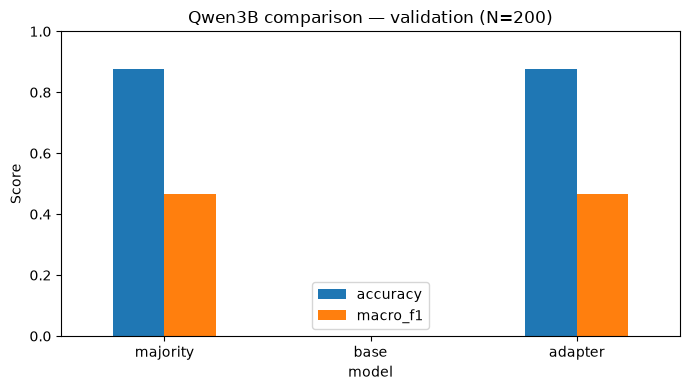

,base,adapter,examples
0,False,False,25
1,False,True,175


In [5]:
if predictions is not None:
    import matplotlib.pyplot as plt
    metrics = pd.DataFrame(summarize(rows)).set_index("model")
    ax = metrics[["accuracy", "macro_f1"]].plot.bar(ylim=(0, 1), rot=0, figsize=(7, 4))
    ax.set_title(f"Qwen3B comparison — {protocol['split']} (N={len(protocol['ids'])})")
    ax.set_ylabel("Score")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "comparison.png", dpi=180)
    plt.show()
    paired = predictions[predictions.model.isin(["base", "adapter"])].pivot(index="id", columns="model", values="correct")
    display(paired.groupby(["base", "adapter"]).size().rename("examples").reset_index())


In [6]:
if predictions is not None:
    # Fixed examples chosen before inference, not selected for favorable results.
    demo = predictions[predictions.id.isin(protocol["demo_ids"])]
    display(demo[["id", "model", "label", "raw_output", "valid", "correct"]])


,id,model,label,raw_output,valid,correct
0,final_json/49444.json,majority,True,"{""is_merged"": true}",True,True
1,final_json/49444.json,base,True,constraints from a source.\n pub async fn ...,False,False
2,final_json/49444.json,adapter,True,"{""is_merged"":true}",True,True
3,final_json/13579.json,majority,False,"{""is_merged"": true}",True,False
4,final_json/13579.json,base,False,get => _requestQueueLength;\n set\...,False,False
5,final_json/13579.json,adapter,False,"{""is_merged"":true}",True,False
6,final_json/49373.json,majority,True,"{""is_merged"": true}",True,True
7,final_json/49373.json,base,True,{\n return false;\n ...,False,False
8,final_json/49373.json,adapter,True,"{""is_merged"":true}",True,True
9,final_json/53608.json,majority,False,"{""is_merged"": true}",True,False


## Saved evidence dashboard — no inference required
Run these cells with `RUN_INFERENCE=False`. They read completed predictions and the training log; no GPU is needed. Figures are exported as PNG and PDF to `OUTPUT_DIR/figures`, with supporting CSV tables. Strict scores remain unchanged. `False` / `True` are dataset merge-status labels, not verified code-quality judgments.

In [7]:
import matplotlib.pyplot as plt
import numpy as np
FIGURE_DIR = OUTPUT_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
def save_figure(fig, name):
    fig.tight_layout()
    for extension in ("png", "pdf"):
        fig.savefig(FIGURE_DIR / f"{name}.{extension}", dpi=180, bbox_inches="tight")
    plt.show()
    plt.close(fig)

### Why can the base score zero?
A zero strict score can mean an output-format failure, not that every underlying judgment is wrong. The required answer is exactly `{"is_merged": true}` or `false`; Markdown fences, prose, code, and unfinished answers are invalid. Inspect raw responses below before interpreting accuracy.

The current inference implementation right-truncates the fully formatted chat. Long inputs can therefore lose the user-message ending and assistant-generation marker, encouraging code continuation. A 32-token output cap can also cut answers short. The diagnostics show these risk indicators, not proven causes for every failure. Fixing prompt construction or output limits requires a separately versioned protocol and rerunning **both** models; do not overwrite or silently rescore the original experiment.

,examples,valid_outputs,strict_correct,input_truncation_rate,invalid_outputs,at_output_limit_rate
model,,,,,,
adapter,200,200,175,0.59,0,0.00
base,200,0,0,0.59,200,0.58
majority,200,200,175,NaN,0,0.00


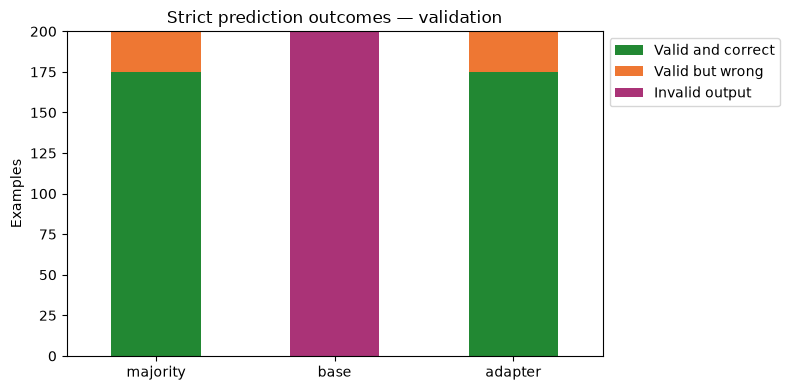

base: 200 invalid responses. First five in frozen evaluation order:


,id,label,raw_output,output_tokens,truncated
1,final_json/49444.json,True,"constraints from a source.\n pub async fn from_source(\n source: &RequirementsSource,\n client_builder: &BaseClientBuilder<'_>,\n )",32,True
4,final_json/13579.json,False,"get => _requestQueueLength;\n set\n {\n if (value < 0)\n {\n throw new ArgumentOutOfRangeException(nameof(value), value, """,32,True
7,final_json/49373.json,True,{\n return false;\n };\n let Ok(metadata) = rmp_serde::from_slice::<Metadata23>(&metadata) else {\n return false,32,True
10,final_json/53608.json,False,(_clipboardSupported == null)\n {\n _clipboardSupported = RuntimeInformation.IsOSPlatform(OSPlatform.Windows);\n }\n\n if (!_clipboardSupported.Value)\n,32,True
13,final_json/12452.json,True,"```json\n{\n ""is_merged"": false\n}\n```",14,False


adapter: 0 invalid responses. First five in frozen evaluation order:


,id,label,raw_output,output_tokens,truncated


In [8]:
if predictions is not None:
    diagnostics = predictions.groupby("model").agg(
        examples=("id", "size"), valid_outputs=("valid", "sum"),
        strict_correct=("correct", "sum"), input_truncation_rate=("truncated", "mean")
    ) if "truncated" in predictions else predictions.groupby("model").agg(
        examples=("id", "size"), valid_outputs=("valid", "sum"), strict_correct=("correct", "sum"))
    diagnostics["invalid_outputs"] = diagnostics.examples - diagnostics.valid_outputs
    limit = protocol.get("generation", {}).get("max_new_tokens")
    if limit is not None:
        diagnostics["at_output_limit_rate"] = predictions.assign(at_limit=predictions.output_tokens >= limit).groupby("model").at_limit.mean()
    display(diagnostics)
    diagnostics.to_csv(FIGURE_DIR / "output_diagnostics.csv")
    outcomes = []
    for model in ["majority", "base", "adapter"]:
        part = predictions[predictions.model == model]
        outcomes.append([int(part.correct.sum()), int((part.valid & ~part.correct).sum()), int((~part.valid).sum())])
    counts = pd.DataFrame(outcomes, index=["majority", "base", "adapter"], columns=["Valid and correct", "Valid but wrong", "Invalid output"])
    fig, ax = plt.subplots(figsize=(8, 4))
    counts.plot.bar(stacked=True, ax=ax, rot=0, color=["#228833", "#ee7733", "#aa3377"])
    ax.set(ylabel="Examples", title=f"Strict prediction outcomes — {protocol['split']}")
    ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
    save_figure(fig, "output_validity")
    for model in ["base", "adapter"]:
        bad = predictions[(predictions.model == model) & ~predictions.valid]
        print(f"{model}: {len(bad)} invalid responses. First five in frozen evaluation order:")
        with pd.option_context("display.max_colwidth", 350):
            display(bad[[c for c in ["id", "label", "raw_output", "output_tokens", "truncated"] if c in bad]].head(5))

### Label imbalance and prediction collapse
Compare retained train/validation/test label counts from the frozen split manifest against the actual evaluated sample. Test label counts are descriptive metadata, not test predictions. The majority classifier is fixed from **training** labels. A model matching its accuracy while never recognizing the minority class has not demonstrated an improvement.

,False,True
train,7816,30281
validation,533,3264
test,1288,3336
Evaluated validation sample,25,175


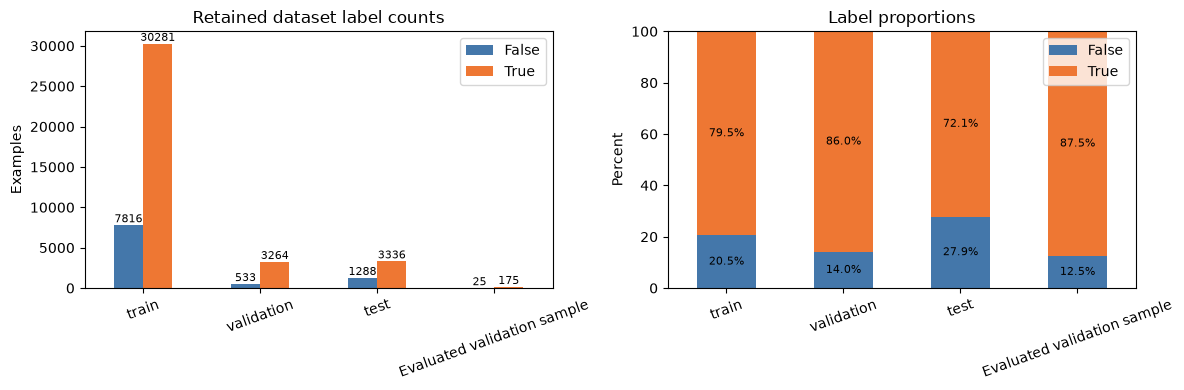

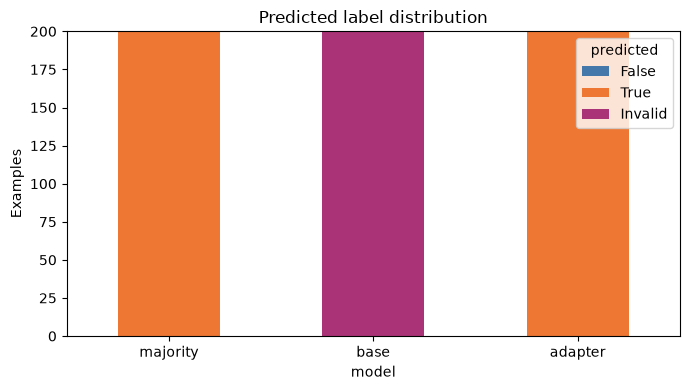

In [9]:
saved_run = json.loads(RUN_MANIFEST.read_text()) if RUN_MANIFEST.exists() else {}
saved_split = saved_run.get("split_manifest")
if saved_split is None and SPLIT_MANIFEST.exists():
    saved_split = json.loads(SPLIT_MANIFEST.read_text())
balance = {}
if saved_split:
    for name in ["train", "validation", "test"]:
        labels = saved_split["summary"][name]["labels"]
        balance[name] = [labels.get("False", 0), labels.get("True", 0)]
if predictions is not None:
    sample = predictions[predictions.model == "majority"]
    balance[f"Evaluated {protocol['split']} sample"] = [int((sample.label == False).sum()), int((sample.label == True).sum())]
if balance:
    balance_table = pd.DataFrame.from_dict(balance, orient="index", columns=["False", "True"])
    display(balance_table)
    balance_table.to_csv(FIGURE_DIR / "label_counts.csv")
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    balance_table.plot.bar(ax=axes[0], color=["#4477aa", "#ee7733"], rot=20)
    axes[0].set(title="Retained dataset label counts", ylabel="Examples")
    for container in axes[0].containers: axes[0].bar_label(container, fontsize=8)
    fractions = balance_table.div(balance_table.sum(axis=1), axis=0) * 100
    fractions.plot.bar(stacked=True, ax=axes[1], color=["#4477aa", "#ee7733"], rot=20)
    axes[1].set(title="Label proportions", ylabel="Percent", ylim=(0, 100))
    for container in axes[1].containers: axes[1].bar_label(container, fmt="%.1f%%", label_type="center", fontsize=8)
    save_figure(fig, "dataset_imbalance")
else:
    print("No split metadata or completed predictions available for label counts.")
if predictions is not None:
    distributions = predictions.assign(predicted=predictions.apply(lambda r: "Invalid" if not r.valid else str(bool(r.prediction)), axis=1))
    table = pd.crosstab(distributions.model, distributions.predicted).reindex(index=["majority", "base", "adapter"], columns=["False", "True", "Invalid"], fill_value=0)
    fig, ax = plt.subplots(figsize=(7, 4))
    table.plot.bar(stacked=True, ax=ax, rot=0, color=["#4477aa", "#ee7733", "#aa3377"])
    ax.set(title="Predicted label distribution", ylabel="Examples")
    save_figure(fig, "prediction_distribution")

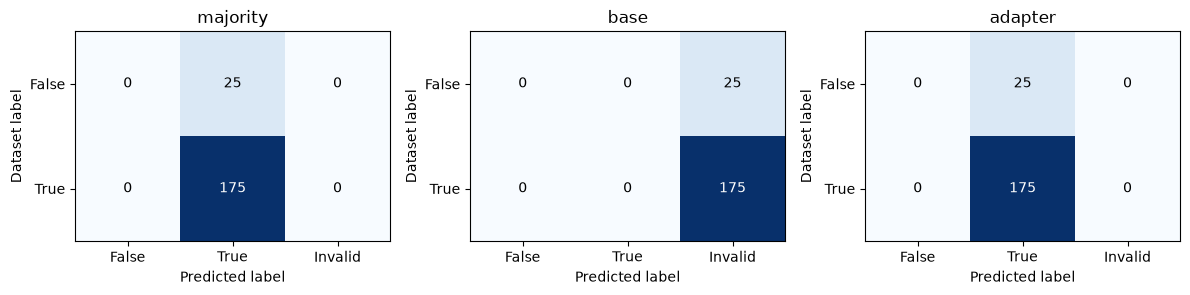

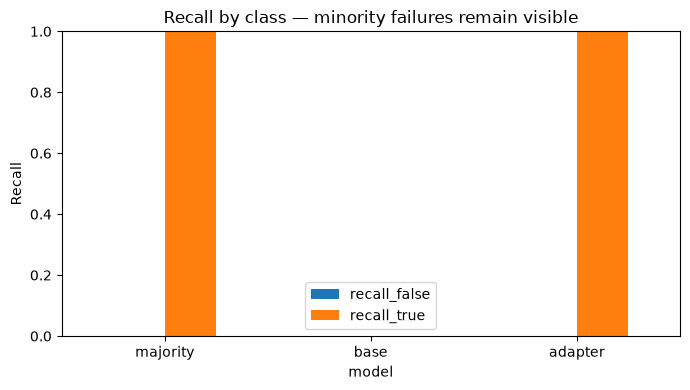

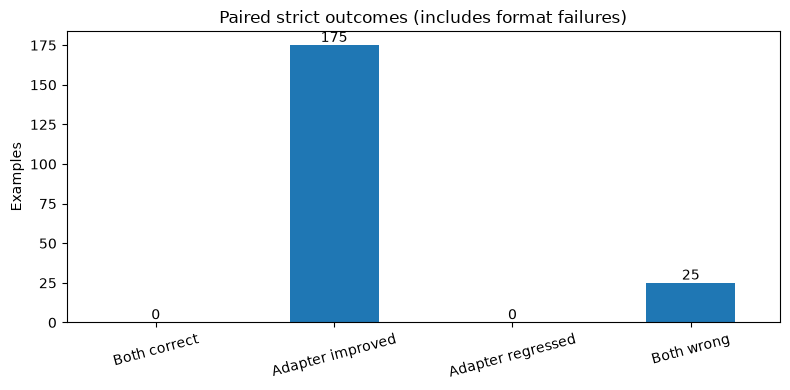

In [10]:
if predictions is not None:
    matrices = []
    for model in ["majority", "base", "adapter"]:
        part = distributions[distributions.model == model]
        matrix = pd.crosstab(part.label, part.predicted).reindex(index=[False, True], columns=["False", "True", "Invalid"], fill_value=0)
        matrices.append(matrix)
        matrix.to_csv(FIGURE_DIR / f"confusion_{model}.csv")
    vmax = max(int(m.to_numpy().max()) for m in matrices)
    fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
    for ax, model, matrix in zip(axes, ["majority", "base", "adapter"], matrices):
        ax.imshow(matrix, vmin=0, vmax=max(1, vmax), cmap="Blues")
        ax.set(xticks=range(3), xticklabels=matrix.columns, yticks=range(2), yticklabels=["False", "True"], xlabel="Predicted label", ylabel="Dataset label", title=model)
        for i in range(2):
            for j in range(3):
                value = int(matrix.iloc[i, j])
                ax.text(j, i, str(value), ha="center", va="center", color="white" if value > vmax/2 else "black")
    save_figure(fig, "confusion_matrices")
    metrics = pd.DataFrame(summarize(rows)).set_index("model")
    fig, ax = plt.subplots(figsize=(7, 4))
    metrics[["recall_false", "recall_true"]].plot.bar(ax=ax, ylim=(0, 1), rot=0)
    ax.set(title="Recall by class — minority failures remain visible", ylabel="Recall")
    save_figure(fig, "class_recall")
    paired = predictions[predictions.model.isin(["base", "adapter"])].pivot(index="id", columns="model", values="correct")
    counts = pd.Series({"Both correct": int((paired.base & paired.adapter).sum()),
                        "Adapter improved": int((~paired.base & paired.adapter).sum()),
                        "Adapter regressed": int((paired.base & ~paired.adapter).sum()),
                        "Both wrong": int((~paired.base & ~paired.adapter).sum())})
    fig, ax = plt.subplots(figsize=(8, 4))
    counts.plot.bar(ax=ax, rot=15)
    ax.set(title="Paired strict outcomes (includes format failures)", ylabel="Examples")
    ax.bar_label(ax.containers[0])
    save_figure(fig, "paired_outcomes")

### Training history and validation curves
These plots read `ADAPTER_DIR/training_log.jsonl`. No training is started. Logs may contain replayed optimizer steps after resume: the main curves retain the last observed value **per step and metric**, while the raw log remains unchanged. Session boundaries are marked; these curves are not a reconstruction of wall-clock compute. Malformed/incomplete log lines are counted and skipped.

Training loss is logged during updates; validation loss is measured separately. Completion token accuracy and exact match use teacher-forced targets and are **not** generated classification accuracy. Generated accuracy/F1 are plotted separately only when present in the log. Loss decreases alone do not establish minority-class performance.

Loaded 15740 log events; skipped 0 incomplete/malformed lines.


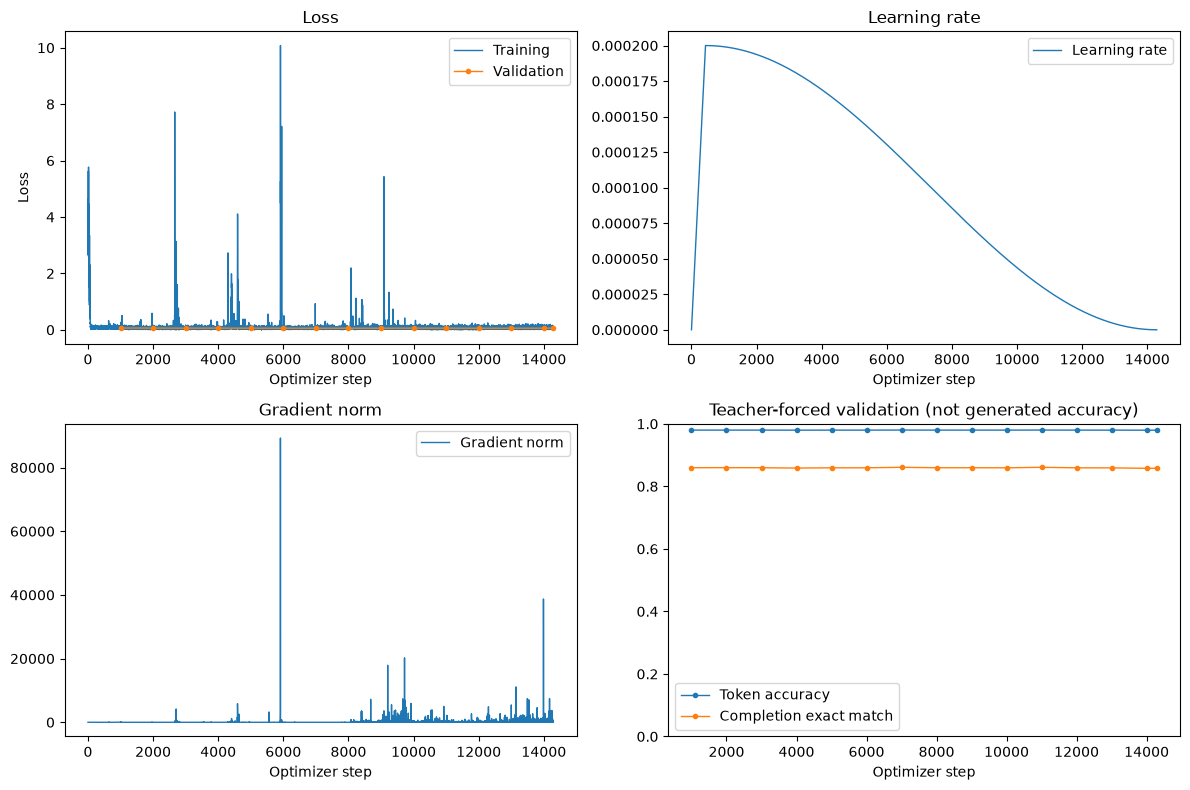

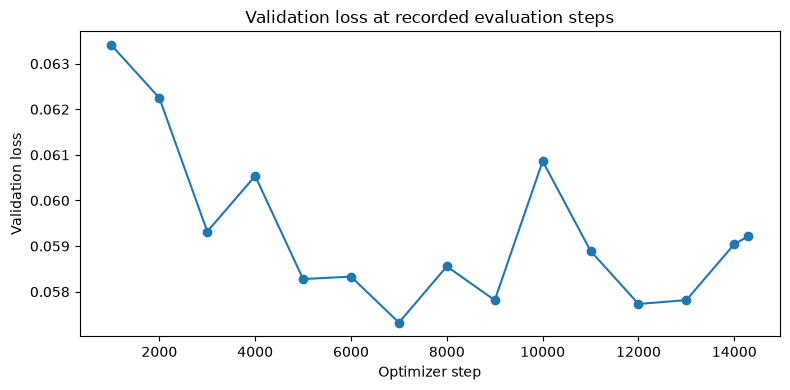

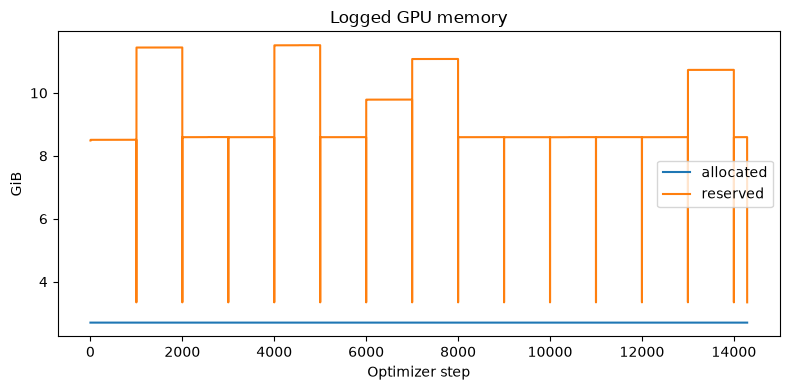

,timestamp_utc,phase,identity,model,examples,accuracy,macro_f1,malformed_rate,precision_false,precision_true,recall_false,recall_true,support_false,support_true
0,2026-10-31T02:43:26.058684+00:00,base,8d3e98511f8612106c36a3a6a1ad6d1a977a5451342d38...,base,200,0.00,0.000000,1.0,0.0,0.000000,0.0,0.000000,25,175
1,2026-10-31T20:00:41.235087+00:00,adapter,ba95f5b5a100811a34678c00b9527e4bbd5bcfc80723b6...,adapter,200,0.87,0.465241,0.0,0.0,0.874372,0.0,0.994286,25,175


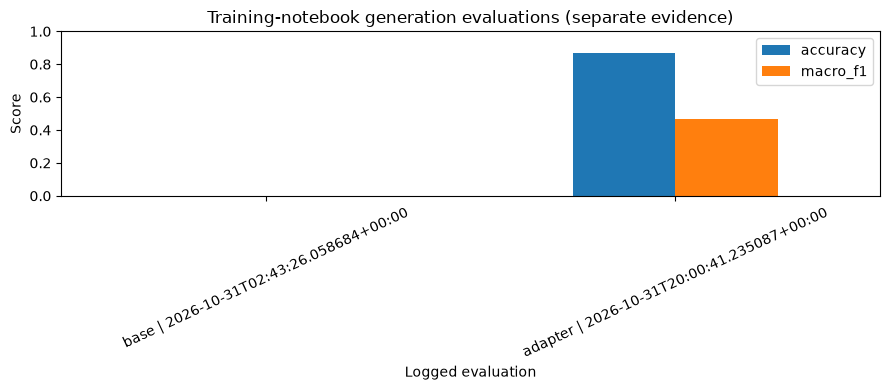

Do not combine these with paired comparison scores unless IDs, prompts, and protocol match.
Figures and supporting tables: /root/workspace/CS536_Project/results/midpoint/qwen3b_validation_v1/figures


In [11]:
LOG_PATH = ADAPTER_DIR / "training_log.jsonl"
if not LOG_PATH.exists():
    print(f"Training log not found: {LOG_PATH}. Copy it with the adapter to plot training history.")
else:
    events, skipped = [], 0
    for line in LOG_PATH.read_text().splitlines():
        if not line.strip(): continue
        try: events.append(json.loads(line))
        except json.JSONDecodeError: skipped += 1
    print(f"Loaded {len(events)} log events; skipped {skipped} incomplete/malformed lines.")
    history = pd.DataFrame([e for e in events if e.get("event") == "metrics" and "step" in e])
    def series(key):
        if key not in history: return pd.DataFrame(columns=["step", key])
        return history[["step", key]].dropna().drop_duplicates("step", keep="last").sort_values("step")
    if history.empty:
        print("No step-level training metrics found.")
    else:
        history.to_csv(FIGURE_DIR / "training_metrics_observed.csv", index=False)
        boundaries = history.groupby("session", sort=False).step.first().tolist() if "session" in history else []
        fig, axes = plt.subplots(2, 2, figsize=(12, 8))
        panels = [("Loss", [("loss", "Training"), ("eval_loss", "Validation")]),
                  ("Learning rate", [("learning_rate", "Learning rate")]),
                  ("Gradient norm", [("grad_norm", "Gradient norm")]),
                  ("Teacher-forced validation (not generated accuracy)", [("eval_completion_token_accuracy", "Token accuracy"), ("eval_completion_exact_match", "Completion exact match")])]
        for ax, (title, keys) in zip(axes.flat, panels):
            found = False
            for key, label in keys:
                points = series(key)
                if not points.empty:
                    ax.plot(points.step, points[key], label=label, marker="o" if key.startswith("eval_") else None, markersize=3, linewidth=1)
                    found = True
            for boundary in boundaries[1:]: ax.axvline(boundary, color="gray", linestyle=":", alpha=.5)
            ax.set(title=title, xlabel="Optimizer step")
            if found: ax.legend()
            else: ax.text(.5, .5, "Not recorded", transform=ax.transAxes, ha="center")
        axes[0,0].set_ylabel("Loss")
        axes[1,1].set_ylim(0, 1)
        save_figure(fig, "training_history")
        points = series("eval_loss")
        if not points.empty:
            fig, ax = plt.subplots(figsize=(8, 4))
            ax.plot(points.step, points.eval_loss, marker="o")
            ax.set(title="Validation loss at recorded evaluation steps", xlabel="Optimizer step", ylabel="Validation loss")
            save_figure(fig, "validation_loss")
        fig, ax = plt.subplots(figsize=(8, 4))
        found = False
        for key in ["cuda_allocated_bytes", "cuda_reserved_bytes"]:
            points = series(key)
            if not points.empty:
                ax.plot(points.step, points[key] / 1024**3, label=key.replace("cuda_", "").replace("_bytes", ""))
                found = True
        if found:
            ax.set(title="Logged GPU memory", xlabel="Optimizer step", ylabel="GiB")
            ax.legend()
            save_figure(fig, "gpu_memory")
        else: plt.close(fig)
    generation = []
    for event in events:
        if event.get("event") == "generation_evaluation":
            generation.append({"timestamp_utc": event.get("timestamp_utc"), "phase": event.get("phase"),
                               "identity": event.get("identity"), **event.get("metrics", {})})
    if generation:
        gen = pd.DataFrame(generation)
        display(gen)
        gen.to_csv(FIGURE_DIR / "training_generation_evaluations.csv", index=False)
        fig, ax = plt.subplots(figsize=(9, 4))
        gen.assign(label=gen.phase.astype(str) + " | " + gen.timestamp_utc.astype(str)).set_index("label")[["accuracy", "macro_f1"]].plot.bar(ax=ax, ylim=(0,1), rot=25)
        ax.set(title="Training-notebook generation evaluations (separate evidence)", ylabel="Score", xlabel="Logged evaluation")
        save_figure(fig, "training_generation_metrics")
        print("Do not combine these with paired comparison scores unless IDs, prompts, and protocol match.")
print(f"Figures and supporting tables: {FIGURE_DIR}")

## Interpretation
Report strict accuracy alongside format validity, class recall, class balance, and the majority baseline. These results do not establish general coding-agent ability or the main learned-selector contribution. Preserve old caches when changing the inference protocol.
